# Lab 10: Community composition — Single Large or Several Small (SLOSS)?

### **This is an imaginary exercise.**

Suppose Maine can protect **1,000 km²** in one reserve or divide the same area
among three smaller reserves. Which strategy is better depends on how we
measure biodiversity and what we want to conserve.

This is the **SLOSS** question: **Single Large or Several Small**. We will use
imaginary reserves and real amphibian records to explore the
[week 10 topics](../schedule/week-10.md).

By the end of this lab you should be able to:

- calculate richness, Shannon diversity, and Simpson diversity;
- distinguish alpha, beta, and gamma diversity;
- calculate endemism and rarity metrics;
- map biodiversity at different grid grains and moving-window sizes;
- explain how scale and sampling affect a reserve comparison.

**Before beginning:**

- Would you prioritize total number of species (species richness), rare species (endemics), or areas with more even abundances per species?
- Given this, would you choose to protect one large (OL) reserve or several small (SS) reserves?
- What other advantages or disadvantages might the OL vs SS strategies have?

## 0. Install and import packages necessary packages

All the packages we are using today are things we have seen before.

We will also set a couple variables (`AREA_CRS` and `COLORS`) that we can use later
to make things a bit cleaner.

In [1]:
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from shapely.geometry import box

# Albers Equal Area Conic projection in units of meters
AREA_CRS = "EPSG:5070"
# Custom colors to make it pretty
COLORS = {"single_large": "#287c8e", "several_small": "#b56b32"}

## 1. Load the data

[`ME_ImaginaryParks.geojson`](../data/ME_ImaginaryParks.geojson) contains four
imaginary parks and their occurrence records. Each point already has a park assignment.

| Imaginary park | Strategy | Area (km²) | Location |
| --- | --- | ---: | --- |
| Alder Basin Preserve | Single large | 1,000 | Central interior |
| Fern Hollow Woods | Several small | 400 | Southwest |
| Coldwater Ridge Preserve | Several small | 300 | Northern interior |
| Spruce Lantern Reserve | Several small | 300 | Eastern interior |

Run this notebook from `docs/labs` using the course Python environment.
See the [dataset notes](../data/ME_ImaginaryParks.md) for how the parks were made.

In [27]:
features = gpd.read_file("../data/ME_ImaginaryParks.geojson")
parks = features[features.feature_type == "park"].copy().to_crs(AREA_CRS).set_index("park_id")
records = features[features.feature_type == "occurrence"].copy().to_crs(AREA_CRS)

print("# of occurrence records: ", records.shape)

# Keep a list of the parks in order for later
park_order = list(parks.index)

parks.explore()

# of occurrence records:  (846, 15)


## 2. Map the parks

Use the equal-area projection EPSG:5070 to measure area in square kilometers.
Both strategies protect 1,000 km².

scenario
several_small    1000.000809
single_large     1000.001413
Name: measured_km2, dtype: float64

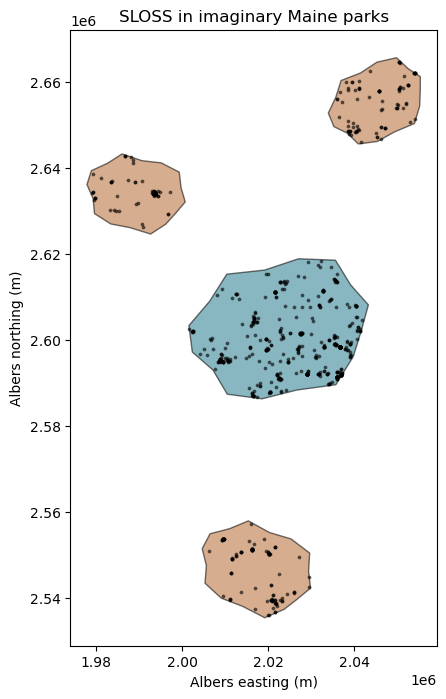

In [28]:
parks = parks.assign(measured_km2=parks.area / 1e6)

display(parks.groupby("scenario").measured_km2.sum())

fig, ax = plt.subplots(figsize=(8, 8))

#To plot ME boundary
#maine = gpd.read_file("ME_ShapeFiles/Maine_State_Boundary.shp").to_crs(AREA_CRS)
#maine.plot(ax=ax, color="#f1f0e9", edgecolor="#8c8c80", linewidth=0.5)

for strategy, group in parks.groupby("scenario"):
    group.plot(ax=ax, color=COLORS[strategy], alpha=0.55, edgecolor="black")

records.plot(ax=ax, color="black", markersize=3, alpha=0.5)

# Annotate parks by name
#for row in parks.itertuples():
#    anchor = row.geometry.representative_point()
#    ax.annotate(f"{row.Index}: {row.park_name}", (anchor.x, anchor.y),
#                xytext=(8, 10), textcoords="offset points", fontsize=8)

ax.set(title="SLOSS in imaginary Maine parks",
       xlabel="Albers easting (m)", ylabel="Albers northing (m)")
plt.show()

## 3. Build a community matrix

Our communities are the species **recorded in each park**. These are not comprehensive surveys,
there are problems with unequal sampling effort, but we will just go ahead with what we have.

In the **community matrix**, rows are parks, columns are species, and values
are record counts. Convert counts to presence/absence to compare species lists.

species,Ambystoma maculatum,Anaxyrus americanus,Aquarana clamitans,Boreorana sylvatica,Dryophytes versicolor,Eurycea bislineata,Hemidactylium scutatum,Lithobates catesbeianus,Lithobates palustris,Lithobates pipiens,Notophthalmus viridescens,Plethodon cinereus,Pseudacris crucifer,Rana arvalis
park_id,,,,,,,,,,,,,,
SL,24,75,52,87,32,2,2,61,50,0,11,20,88,1
SS1,4,23,19,8,9,0,0,13,13,0,4,5,18,0
SS2,4,9,11,11,5,1,0,12,19,1,3,4,9,0
SS3,11,23,11,16,9,1,0,6,24,0,9,5,21,0


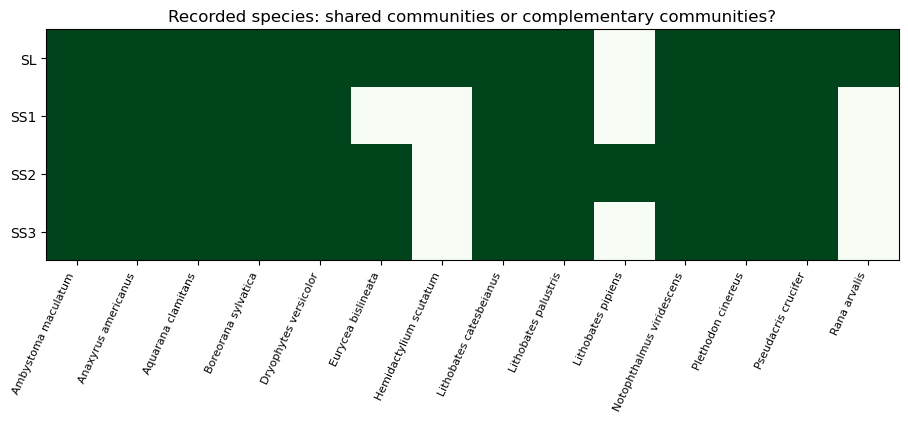

In [29]:
community = pd.crosstab(records.park_id, records.species).reindex(park_order, fill_value=0)
presence = community.gt(0)
display(community)

fig, ax = plt.subplots(figsize=(11, 3))
image = ax.imshow(presence.astype(int), aspect="auto", cmap="Greens", vmin=0, vmax=1)
ax.set(yticks=range(len(community)), yticklabels=community.index,
       xticks=range(len(community.columns)), xticklabels=community.columns,
       title="Recorded species: shared communities or complementary communities?")
plt.setp(ax.get_xticklabels(), rotation=65, ha="right", fontsize=8)
plt.show()

## 4. Richness, Shannon, and Simpson diversity

Let $p_i=n_i/N$ be the fraction of records belonging to species $i$.

| Metric | Calculation | Measures |
| --- | --- | --- |
| Richness, $S$ | Number of species recorded | Species count |
| Shannon, $H'$ | $-\sum_i p_i\ln p_i$ | Diversity of record frequencies |
| Gini–Simpson | $1-\sum_i p_i^2$ | Probability that two independent draws differ in species |

Higher values indicate greater diversity. For a fixed richness, more even
frequencies give higher Shannon and Simpson values. We use natural logs and
the **1 − D** convention for Simpson
([definitions](https://vegandevs.github.io/vegan/reference/diversity.html)).
Cells without records receive missing diversity values.

In [31]:
def diversity(counts):
    """One row per spatial unit; no records -> NaN diversity, zero n_records."""
    total = counts.sum(axis=1)
    proportions = counts.div(total.replace(0, np.nan), axis=0)
    positive = proportions.where(proportions.gt(0))
    return pd.DataFrame({
        "n_records": total.astype(int),
        "richness": counts.gt(0).sum(axis=1).where(total.gt(0)),
        "shannon": -(positive * np.log(positive)).sum(axis=1, min_count=1),
        "simpson": (1 - proportions.pow(2).sum(axis=1)).where(total.gt(0)),
    })

park_metrics = parks[["park_name", "scenario", "area_km2"]].join(diversity(community))
display(park_metrics.round(3))

example = pd.DataFrame([[10, 10, 10], [28, 1, 1]],
                       index=["even", "dominated"])
display(diversity(example).round(3))

,park_name,scenario,area_km2,n_records,richness,shannon,simpson
park_id,,,,,,,
SL,Alder Basin Preserve,single_large,1000.0,505,13,2.196,0.875
SS1,Fern Hollow Woods,several_small,400.0,116,10,2.147,0.870
SS2,Coldwater Ridge Preserve,several_small,300.0,89,12,2.236,0.877
SS3,Spruce Lantern Reserve,several_small,300.0,136,11,2.208,0.877


,n_records,richness,shannon,simpson
even,30,3,1.099,0.667
dominated,30,3,0.291,0.127


Does the richest park also have the highest Shannon diversity? What would
100 additional bullfrog records change?

## 5. Alpha, beta, and gamma diversity

- **Alpha:** mean park richness within a strategy.
- **Gamma:** pooled richness across that strategy, counting each species once.
- **Multiplicative beta:** $\gamma/\bar\alpha$. Identical species lists give 1;
  disjoint lists across $k$ parks give $k$.

Complementary species can increase gamma across small parks. Adding their
richnesses would count shared species repeatedly.

Park sizes differ, and beta for a single park is necessarily 1. Later we will
compare both strategies using a common grid grain.

In [33]:
strategy_order = ["single_large", "several_small"]
strategy_counts = (community.assign(scenario=parks.scenario)
                   .groupby("scenario").sum().reindex(strategy_order))
strategy_metrics = diversity(strategy_counts).rename(columns={"richness": "gamma_richness"})
strategy_metrics["protected_km2"] = area_by_strategy
strategy_metrics["mean_park_alpha"] = park_metrics.groupby("scenario").richness.mean()
strategy_metrics["beta_ratio_parks"] = strategy_metrics.gamma_richness / strategy_metrics.mean_park_alpha
strategy_metrics["sum_park_richness"] = park_metrics.groupby("scenario").richness.sum()
display(strategy_metrics.round(3))

single_species = set(strategy_counts.columns[strategy_counts.loc["single_large"].gt(0)])
small_species = set(strategy_counts.columns[strategy_counts.loc["several_small"].gt(0)])
print("Recorded only in the single-large strategy:", sorted(single_species - small_species))
print("Recorded only in the several-small strategy:", sorted(small_species - single_species))
print("Recorded in both:", len(single_species & small_species))

,n_records,gamma_richness,shannon,simpson,protected_km2,mean_park_alpha,beta_ratio_parks,sum_park_richness
scenario,,,,,,,,
single_large,505,13,2.196,0.875,1000.001,13.0,1.000,13
several_small,341,12,2.238,0.882,1000.001,11.0,1.091,33


Recorded only in the single-large strategy: ['Hemidactylium scutatum', 'Rana arvalis']
Recorded only in the several-small strategy: ['Lithobates pipiens']
Recorded in both: 11


**Jaccard dissimilarity** compares species lists:
$d_J = 1 - |A\cap B|/|A\cup B|$. Zero means identical lists; one means no
shared species. Differences can reflect both species replacement and unequal richness.

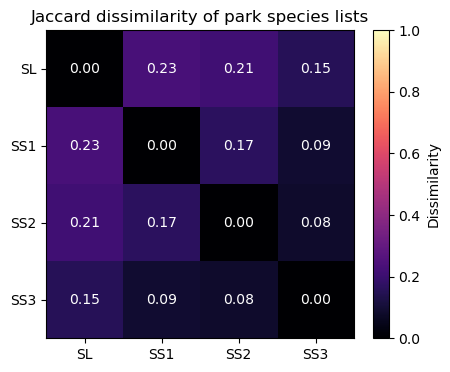

In [34]:
jaccard = pd.DataFrame(index=park_order, columns=park_order, dtype=float)
for a in park_order:
    for b in park_order:
        shared = (presence.loc[a] & presence.loc[b]).sum()
        pooled = (presence.loc[a] | presence.loc[b]).sum()
        jaccard.loc[a, b] = 1 - shared / pooled

fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(jaccard, vmin=0, vmax=1, cmap="magma")
ax.set(xticks=range(4), xticklabels=park_order, yticks=range(4),
       yticklabels=park_order, title="Jaccard dissimilarity of park species lists")
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{jaccard.iloc[i, j]:.2f}", ha="center", va="center", color="white")
fig.colorbar(image, ax=ax, label="Dissimilarity")
plt.show()

## 6. Compare equal numbers of records

Draw the same number of records from each strategy without replacement and
repeat 300 times. This **record-based rarefaction** checks sensitivity to record
totals; it does not equalize survey effort or detectability. The reported
quantiles describe the resampling distribution, not uncertainty in true richness.

In [36]:
rng = np.random.default_rng(597)
record_pools = {strategy: group.species.to_numpy()
                for strategy, group in records.groupby("scenario")}
equal_n = min(map(len, record_pools.values()))
rarefaction_rows = []
for strategy in strategy_order:
    pool = record_pools[strategy]
    draws = [len(np.unique(rng.choice(pool, size=equal_n, replace=False)))
             for _ in range(300)]
    rarefaction_rows.append({"scenario": strategy, "records_drawn": equal_n,
                            "mean_richness": np.mean(draws),
                            "q025": np.quantile(draws, 0.025),
                            "q975": np.quantile(draws, 0.975)})
rarefaction = pd.DataFrame(rarefaction_rows).set_index("scenario")
display(rarefaction.round(2))

,records_drawn,mean_richness,q025,q975
scenario,,,,
single_large,341,12.46,11.0,13.0
several_small,341,12.00,12.0,12.0


## 7. Endemism and rarity

**Endemism** is geographic restriction to an area. Here we measure restriction
within the four-park sample; these records cannot establish true species ranges.

Let $r_i$ be the number of parks recording species $i$.

| Metric | Calculation |
| --- | --- |
| Sample-exclusive richness | Number of species with $r_i=1$ |
| Weighted endemism (WE) proxy | $\sum_{i\text{ present}}1/r_i$ |
| Corrected WE (CWE) proxy | $WE/S$ |

WE increases with richness and restriction; CWE measures average restriction
([Biodiverse definitions](https://github.com/shawnlaffan/biodiverse/wiki/Indices)).
The park units differ in area, which also affects occupancy.

Define **record-rare** species as those with at most five records across all
four parks. Low reporting need not mean a narrow range or small population.

In [37]:
RARE_THRESHOLD = 5
species_totals = community.sum(axis=0)
rare_species = species_totals.le(RARE_THRESHOLD)

def restriction_metrics(counts):
    incidence = counts.gt(0)
    occupied = incidence.sum(axis=0).replace(0, np.nan)
    richness = incidence.sum(axis=1).replace(0, np.nan)
    we = incidence.mul(1 / occupied, axis=1).sum(axis=1)
    return pd.DataFrame({
        "sample_exclusive": incidence.loc[:, occupied.eq(1)].sum(axis=1).where(richness.notna()),
        "we_proxy": we.where(richness.notna()),
        "cwe_proxy": we / richness,
        "record_rare_richness": incidence.loc[:, rare_species].sum(axis=1).where(richness.notna()),
    })

park_restriction = restriction_metrics(community)
display(park_metrics.join(park_restriction).round(3))
species_context = pd.DataFrame({"records_in_four_parks": species_totals,
                                "parks_recorded": presence.sum(),
                                "record_rare": rare_species})
display(species_context.sort_values(["parks_recorded", "records_in_four_parks"]))

,park_name,scenario,area_km2,n_records,richness,shannon,simpson,sample_exclusive,we_proxy,cwe_proxy,record_rare_richness
park_id,,,,,,,,,,,
SL,Alder Basin Preserve,single_large,1000.0,505,13,2.196,0.875,2,4.833,0.372,3
SS1,Fern Hollow Woods,several_small,400.0,116,10,2.147,0.870,0,2.500,0.250,0
SS2,Coldwater Ridge Preserve,several_small,300.0,89,12,2.236,0.877,1,3.833,0.319,2
SS3,Spruce Lantern Reserve,several_small,300.0,136,11,2.208,0.877,0,2.833,0.258,1


,records_in_four_parks,parks_recorded,record_rare
species,,,
Lithobates pipiens,1,1,True
Rana arvalis,1,1,True
Hemidactylium scutatum,2,1,True
Eurycea bislineata,4,3,True
Notophthalmus viridescens,27,4,False
Plethodon cinereus,34,4,False
Ambystoma maculatum,43,4,False
Dryophytes versicolor,55,4,False
Lithobates catesbeianus,92,4,False


Which species are park-exclusive but not record-rare? How would more records
outside these parks change your interpretation of endemism?

## 8. Grid grain and spatial aggregation

**Grain** is spatial unit size; **extent** is the full area considered. Keep the
four-park extent fixed and compare **5 km and 10 km grids** with the same origin.

Clip cells to park boundaries and count records in each cell. Edge cells have
less area, recorded as `support_km2`. Gray cells have no records.

Recalculate WE and CWE using species occupancy across all grid cells at each
grain. Changing grain changes both local communities and apparent ranges.

In [38]:
def grid_communities(grain_m):
    cell_rows = []
    for park in parks.itertuples():
        xmin, ymin, xmax, ymax = park.geometry.bounds
        for ix in range(int(np.floor(xmin / grain_m)), int(np.floor(xmax / grain_m)) + 1):
            for iy in range(int(np.floor(ymin / grain_m)), int(np.floor(ymax / grain_m)) + 1):
                square = box(ix * grain_m, iy * grain_m, (ix + 1) * grain_m, (iy + 1) * grain_m)
                clipped = square.intersection(park.geometry)
                if clipped.area > 0:
                    cell_rows.append({"cell_id": f"{park.park_id}_{ix}_{iy}",
                                      "park_id": park.park_id, "scenario": park.scenario,
                                      "grain_m": grain_m, "support_km2": clipped.area / 1e6,
                                      "geometry": clipped})
    grid = gpd.GeoDataFrame(cell_rows, crs=AREA_CRS).set_index("cell_id")
    ix = np.floor(records.geometry.x / grain_m).astype(int).astype(str)
    iy = np.floor(records.geometry.y / grain_m).astype(int).astype(str)
    cell_id = records.park_id + "_" + ix + "_" + iy
    counts = pd.crosstab(cell_id, records.species_analysis).reindex(
        index=grid.index, columns=community.columns, fill_value=0
    )
    grid = grid.join(diversity(counts)).join(restriction_metrics(counts))
    return grid, counts

grids, grid_counts = {}, {}
for grain in [5000, 10000]:
    grids[grain], grid_counts[grain] = grid_communities(grain)

grain_rows = []
for grain, grid in grids.items():
    for strategy, group in grid.groupby("scenario"):
        counts = grid_counts[grain].loc[group.index]
        gamma = counts.sum().gt(0).sum()
        alpha = group.richness.mean()
        grain_rows.append({"grain_km": grain / 1000, "scenario": strategy,
                           "all_cells": len(group), "cells_with_records": int(group.n_records.gt(0).sum()),
                           "records": int(group.n_records.sum()), "gamma": gamma,
                           "mean_sampled_cell_alpha": alpha,
                           "beta_ratio_sampled_cells": gamma / alpha})
grain_summary = pd.DataFrame(grain_rows)
display(grain_summary.round(3))

AttributeError: 'Pandas' object has no attribute 'park_id'

Gamma should stay fixed across grains, while alpha and beta can change.
Here alpha is the mean richness of cells **with records**, giving each sampled
cell equal weight despite differences in record count and edge-cell area.

Use a shared color scale for each metric. Panels are zoomed to each park;
consult the area table when comparing reserve sizes.

In [39]:
MAP_METRICS = {
    "richness": "Recorded richness", "shannon": "Shannon (records)",
    "we_proxy": "WE proxy", "cwe_proxy": "Corrected WE proxy",
    "record_rare_richness": "Record-rare richness",
}

def map_panels(layers, metric, title):
    """Rows = grains/windows, columns = parks; one common color scale."""
    vmax = max(layer[metric].max() for layer in layers.values())
    fig, axes = plt.subplots(len(layers), len(parks), figsize=(13, 3.0 * len(layers)),
                             squeeze=False, layout="constrained")
    for row, (label, layer) in enumerate(layers.items()):
        for col, park_id in enumerate(park_order):
            ax = axes[row, col]
            subset = layer.loc[layer.Index.eq(park_id)].copy()
            subset.loc[subset.n_records.eq(0), metric] = np.nan
            subset.plot(ax=ax, column=metric, cmap="viridis", vmin=0, vmax=vmax,
                        edgecolor="white", linewidth=0.25,
                        missing_kwds={"color": "#d9d9d9", "label": "No records"})
            parks.loc[parks.Index.eq(park_id)].boundary.plot(ax=ax, color="black", linewidth=0.7)
            ax.set_title(f"{park_id} · {label}", fontsize=10)
            ax.set_axis_off()
    fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(0, vmax), cmap="viridis"),
                 ax=axes.ravel().tolist(), shrink=0.65, label=title)
    fig.suptitle(title + " (gray = no records)", fontsize=13)
    return fig

for metric, title in MAP_METRICS.items():
    map_panels({f"{grain // 1000} km grid": grid for grain, grid in grids.items()}, metric, title)
    plt.show()

ValueError: max() arg is an empty sequence

Try mapping `simpson` and `sample_exclusive` with `map_panels`.
Compare WE and CWE with richness before interpreting hotspots.

In [ ]:
map_panels({f"{grain // 1000} km grid": grid for grain, grid in grids.items()},
           "n_records", "Occurrence records per cell")
plt.show()

## 9. Moving-window diversity

Keep the 5 km reporting grid. At a point inside each cell, pool records within
**5 km** and **15 km** radii and recalculate diversity.

Restrict each window to its park and measure the area it covers. Larger windows
include more land and records; overlapping windows are not independent.

In [ ]:
def window_communities(radius_m):
    base = grids[5000][["park_id", "scenario", "geometry"]].copy()
    counts = pd.DataFrame(0, index=base.index, columns=community.columns)
    support = pd.Series(index=base.index, dtype=float)
    for cell_id, cell in base.iterrows():
        center = cell.geometry.representative_point()
        in_park = records.loc[records.park_id.eq(cell.park_id)]
        selected = in_park.loc[in_park.geometry.distance(center).le(radius_m)]
        counts.loc[cell_id] = selected.species_analysis.value_counts().reindex(counts.columns, fill_value=0)
        window = center.buffer(radius_m)
        support.loc[cell_id] = window.intersection(park_lookup.loc[cell.park_id, "geometry"]).area / 1e6
    base = base.join(diversity(counts))
    base["window_support_km2"] = support
    base["fraction_circle_in_park"] = support / (np.pi * radius_m ** 2 / 1e6)
    return base

windows = {f"{radius // 1000} km radius": window_communities(radius) for radius in [5000, 15000]}
for metric in ["richness", "shannon"]:
    map_panels(windows, metric, MAP_METRICS[metric] + " in moving windows")
    plt.show()
display(pd.DataFrame({label: layer[["n_records", "window_support_km2", "fraction_circle_in_park"]].mean()
                      for label, layer in windows.items()}).round(3))

Find a cell with no records whose 15 km window has records. What changed:
evidence within the cell, or the neighborhood defining the community?

## 10. Export results

Save tables, gridded GeoJSONs, and maps to `outputs/Lab10`.

In [ ]:
OUTPUT_DIR = Path("outputs/Lab10")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
park_metrics.join(park_restriction).to_csv(OUTPUT_DIR / "park_metrics.csv")
strategy_metrics.to_csv(OUTPUT_DIR / "strategy_metrics.csv")
rarefaction.to_csv(OUTPUT_DIR / "record_rarefaction.csv")
grain_summary.to_csv(OUTPUT_DIR / "grain_summary.csv", index=False)
species_context.to_csv(OUTPUT_DIR / "species_context.csv")
jaccard.to_csv(OUTPUT_DIR / "park_jaccard.csv")

for grain, grid in grids.items():
    grid.drop(columns="geometry").to_csv(OUTPUT_DIR / f"grid_{grain // 1000}km_metrics.csv")
    grid.reset_index().to_crs(4326).to_file(
        OUTPUT_DIR / f"grid_{grain // 1000}km_metrics.geojson", driver="GeoJSON"
    )
for metric, title in MAP_METRICS.items():
    fig = map_panels({f"{grain // 1000} km grid": grid for grain, grid in grids.items()}, metric, title)
    fig.savefig(OUTPUT_DIR / f"{metric}_5km_vs_10km.png", dpi=180, bbox_inches="tight")
    plt.close(fig)
for label, layer in windows.items():
    layer.drop(columns="geometry").to_csv(OUTPUT_DIR / f"window_{label.replace(' ', '_')}.csv")

## Assignment: recommend a reserve strategy

Submit the completed notebook, richness/Shannon/WE/CWE/rarity maps at **5 km and
10 km grains**, and a **400–600 word** interpretation addressing:

1. Your recommendation, using pooled richness, another metric, and rarefaction.
2. Alpha, beta, gamma, and species complementarity in your results.
3. Differences among WE, CWE, and record rarity, including their reference extent.
4. Sensitivity to grid grain and moving-window size.
5. Sampling bias, missing records, and unequal edge-cell areas.

**Extension:** change the rarity threshold, grid origin, year range, or
coordinate-uncertainty cutoff and compare your recommendation.

What additional evidence about habitat, connectivity, or population viability
would you need for a real SLOSS decision?